In [89]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 


In [90]:
df = pd.read_csv('smartcart_customers.csv')

In [91]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [92]:
print('Shape :', df.shape)

Shape : (2240, 22)


In [93]:
print(df.isnull().sum())

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64


# Data Preprocessing

In [94]:
# 1 Handle Missing values 
df['Income'] = df['Income'].fillna(df['Income'].median())

In [95]:
print(df.isnull().sum())

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64


# Feature Engineering 

In [96]:
# 1. Age (using the birth year)
df['Age'] = 2026 - df['Year_Birth']


In [97]:
# 2. Date of joining (reference the newest join customer data )

# fist convert into the pandas date_time formate which is (month-date-year)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst=True)
reference = df['Dt_Customer'].max()

# Now create the column which show the How many days customer joined the Compony of shop 
df['Customer_Tenour_Days'] = (reference - df['Dt_Customer']).dt.days
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenour_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [98]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenour_Days'],
      dtype='str')

In [99]:
# 3. total Spending 

df['Total_Spending'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                        df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenour_Days,Total_Spending
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,8,10,4,7,0,1,69,663,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,1,1,2,5,0,0,72,113,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,1,8,2,10,4,0,0,61,312,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,2,0,4,6,0,0,42,139,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,5,3,6,5,0,0,45,161,422


In [100]:
# 4. combining the kids and the teenager as total Children
df['Total_Children'] = (df['Kidhome'] + df['Teenhome'])
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenour_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [101]:
df['Education'].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [102]:
# Education 
# Undergraduate, Graduate, Postgraduate

df['Education'] = df['Education'].replace( {
    'Basic' : 'Udergraduate' , '2n Cycle' : 'Udergraduate',
    'Graduation' : 'Graduate', 
    'Master' : 'Postgraduate' , 'PhD' : 'Postgraduate' 
})
df['Education'].value_counts()

Education
Graduate        1127
Postgraduate     856
Udergraduate     257
Name: count, dtype: int64

In [103]:
# Maroitial Status

df['Marital_Status'].value_counts()
df['Living_with'] = df['Marital_Status'].replace({
    'Married' : 'Partner', 'Together' : 'Partner', 
    'Single' : 'Alone' , 'Divorced' : 'Single', 
    'Widow' : 'Alone', 'Absurd' : 'Alone', 'YOLO' : 'Alone'
})

df['Living_with'].value_counts()

Living_with
Partner    1444
Alone       564
Single      232
Name: count, dtype: int64

# Drop Unneccesory Columns

In [104]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenour_Days,Total_Spending,Total_Children,Living_with
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [105]:
cols = ['ID', 'Year_Birth', 'Marital_Status', 'Kidhome', 'Teenhome', 'Dt_Customer']
spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

cols_to_drop = cols + spending_cols
df_cleaned = df.drop(cols_to_drop, axis=1)
print('Shape :',df_cleaned.shape)

Shape : (2240, 15)


# Handling the Outliers 

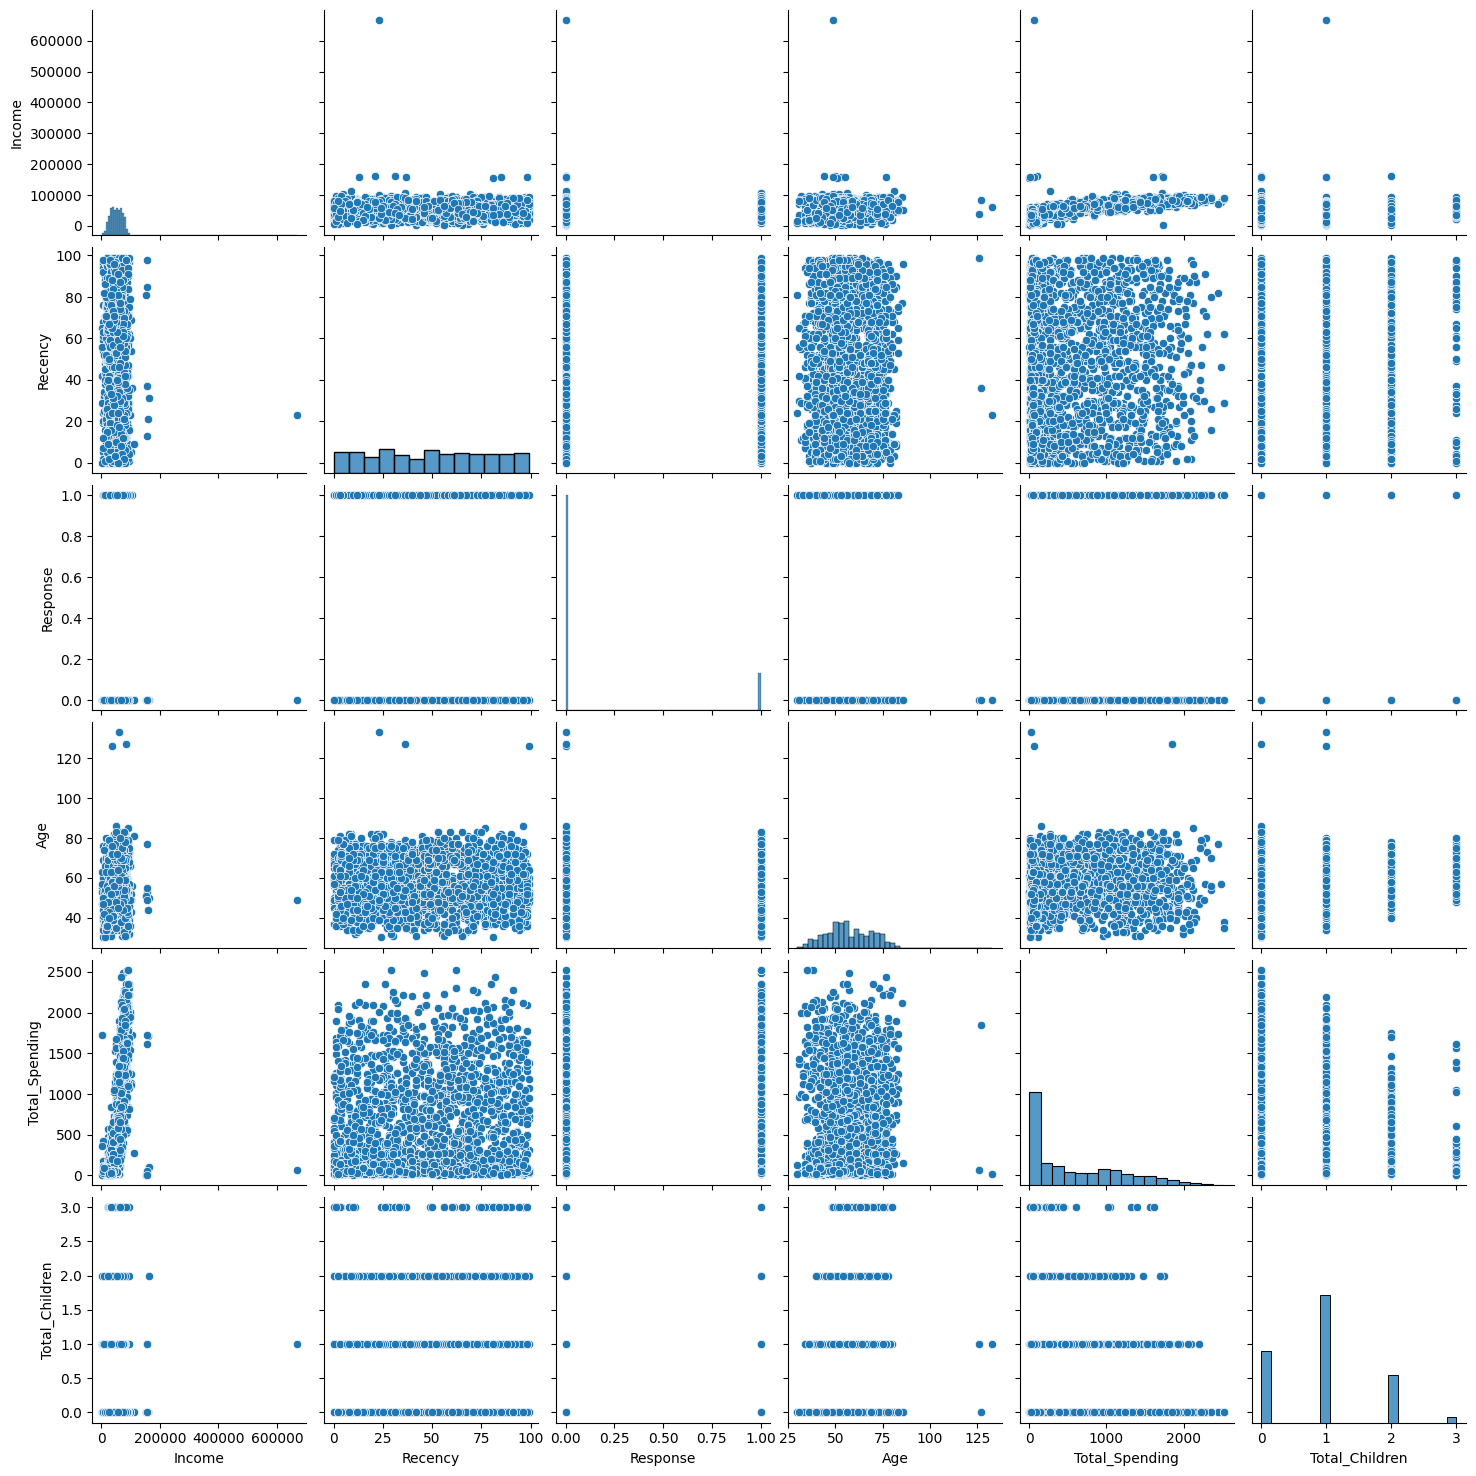

In [106]:
cols = ['Income', 'Recency','Response', 'Age', 'Total_Spending', 'Total_Children']
sns.pairplot(df_cleaned[cols])

In [107]:
# Remove the Outlires 

print('The size of the data with Outliers : ', len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned['Age']) < 90]
df_cleaned = df_cleaned[(df_cleaned['Income']) < 600000]

print("The size of the data without Outliers", len(df_cleaned))

The size of the data with Outliers :  2240
The size of the data without Outliers 2236


# HeatMap

<Axes: >

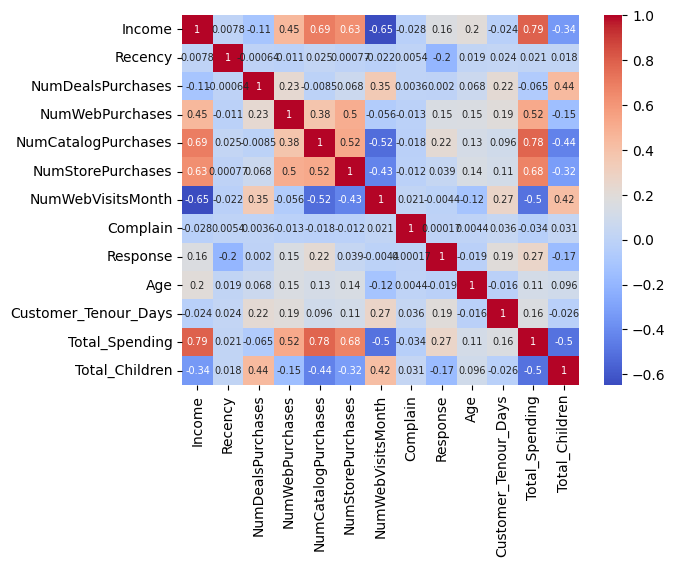

In [108]:
corr = df_cleaned.corr(numeric_only=True)
sns.heatmap(
    corr,
    annot_kws={'size' : 7}, 
    annot=True, 
    cmap='coolwarm'
)

In [109]:
df_cleaned

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenour_Days,Total_Spending,Total_Children,Living_with
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,Graduate,61223.0,46,2,9,3,4,5,0,0,59,381,1341,1,Partner
2236,Postgraduate,64014.0,56,7,8,2,5,7,0,0,80,19,444,3,Partner
2237,Graduate,56981.0,91,1,2,3,13,6,0,0,45,155,1241,0,Single
2238,Postgraduate,69245.0,8,2,6,5,10,3,0,0,70,156,843,1,Partner


# Feature Encoding 

In [110]:
for column in df_cleaned.select_dtypes(include='str'):
    print(df_cleaned[column].value_counts())

Education
Graduate        1126
Postgraduate     855
Udergraduate     255
Name: count, dtype: int64
Living_with
Partner    1442
Alone       563
Single      231
Name: count, dtype: int64


In [111]:
# One Hot Encoding
# In Clustering No need to use drop_first because there is no problem of multicolenearity 
df_cleaned =  pd.get_dummies(df_cleaned, columns=['Education', 'Living_with'] , dtype=bool)


In [112]:
df_cleaned.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenour_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Udergraduate,Living_with_Alone,Living_with_Partner,Living_with_Single
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,True,False,False,True,False,False
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,True,False,False,True,False,False
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,True,False,False,False,True,False
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,True,False,False,False,True,False
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,False,True,False,False,True,False


# Scaling 

In [113]:
# Scaling the data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = df_cleaned
X_scaled = scaler.fit_transform(X)

# Visualization 

In [114]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)
pca.explained_variance_ratio_

array([0.2194243 , 0.10027939, 0.09802581])

Text(0.5, 0.92, '3d Projection')

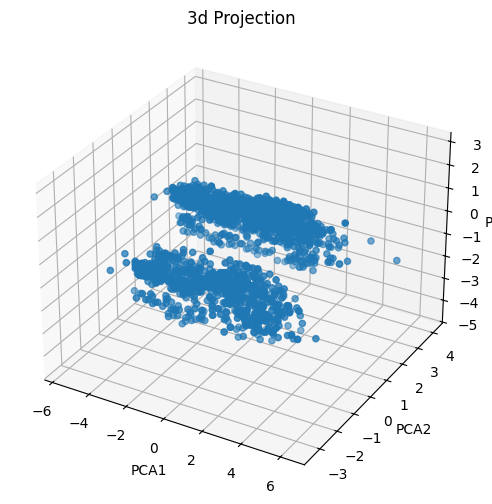

In [115]:
# Plot 
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:,2])
ax.set_xlabel('PCA1')
ax.set_ylabel('PCA2')
ax.set_zlabel('PCA3')
ax.set_title('3d Projection')

# Analyze the K Value 
1. Elbow Method

In [116]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k , random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)


Text(0.5, 1.0, 'Graph Between K_value and WCSS')

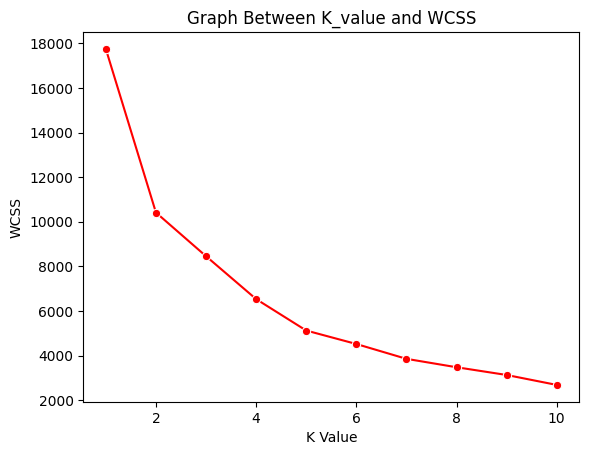

In [117]:
sns.lineplot(x=range(1, 11), y=wcss, marker='o', c='r')
plt.xlabel('K Value')
plt.ylabel('WCSS')
plt.title('Graph Between K_value and WCSS')

In [118]:
knee = KneeLocator(range(1, 11), wcss, direction='decreasing', curve='convex')
print('Best K = ',knee.knee)

Best K =  4


In [119]:
# Silhouette score 
from sklearn.metrics import silhouette_score
scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

<Axes: >

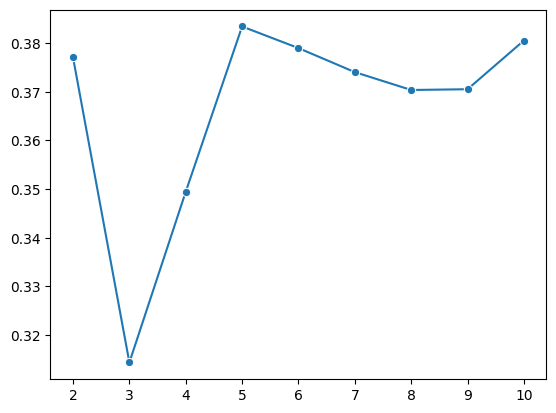

In [120]:
sns.lineplot(
    x= range(2, 11), 
    y = scores, 
    marker = 'o'
)


Text(0, 0.5, 'BLuse WCSS and Red Slhouette Score')

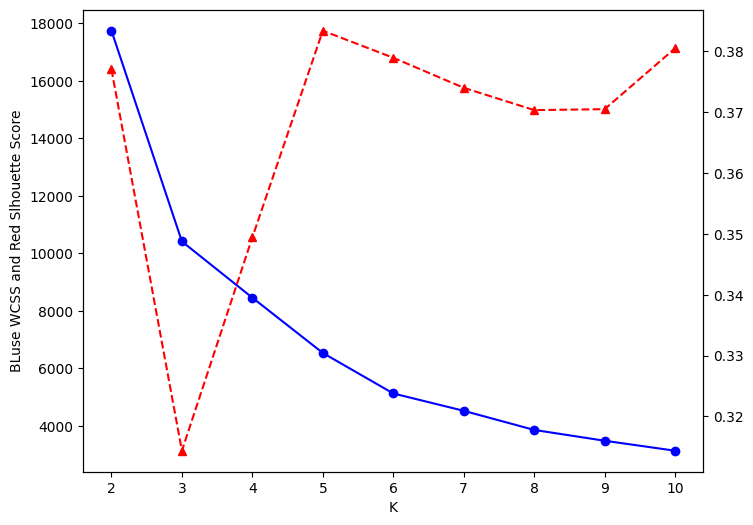

In [121]:
# Combining plot 

k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker='o', color = 'blue')

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker='^', linestyle='--', color = 'red')


ax1.set_xlabel('K')
ax1.set_ylabel('BLuse WCSS and Red Slhouette Score')

In [122]:
# Where the both line intersects we choose the nearest point 
# here Optimal value of k is 4 

# Using the Clustering Algorithms 

In [123]:
# 1. K means 


kmeans = KMeans(n_clusters=4)
labels_kmeans = kmeans.fit_predict(X_pca)

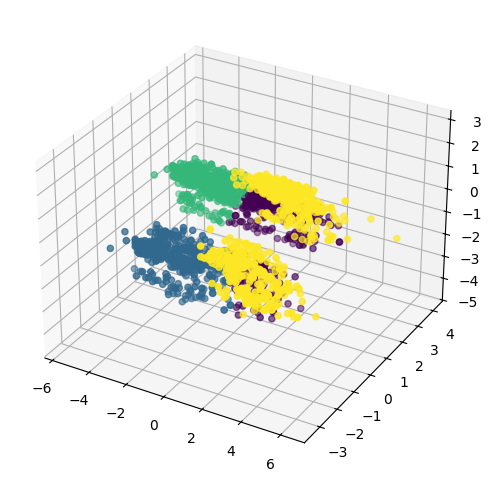

In [124]:
# Visualize the CLusters 
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels_kmeans)

In [125]:
# 2. Hierarchical Clustering 
from sklearn.cluster import AgglomerativeClustering
aglo = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_aglo = aglo.fit_predict(X_pca)


Text(0.5, 0.92, 'PCA')

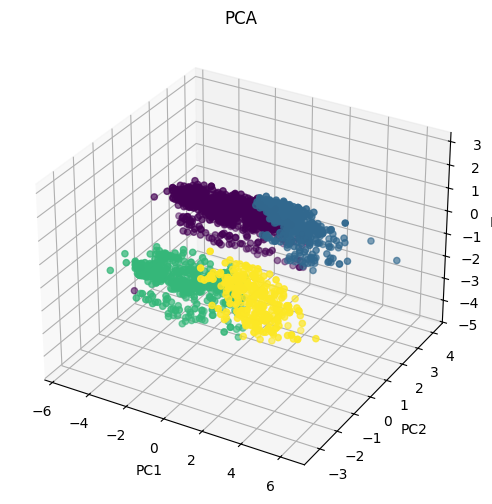

In [127]:
# Visualization 
# Visualize the CLusters 
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels_aglo)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title('PCA')

# For this dataset Aglomerative Hierarchical Clustering Algorithm Perform Better 
